In [1]:
import os
import pathlib

PATH = '/kaggle/input/datasets/zimransohail/satellite-land-cover-classification/dataset/landcover_dataset'
TEST = str(pathlib.Path(PATH, 'test'))
TRAIN = str(pathlib.Path(PATH, 'train'))
VALID = str(pathlib.Path(PATH, 'val'))

os.listdir(path=PATH)

['val', 'test', 'train']

We want to use ResNeXt image embeddings for both EDA and classification, so let's add some code to get them for us.

In [2]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np


DEVICE = torch.device('cpu')
OUTPUT_SIZE = 2048

model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V2)

extraction_layer = model._modules.get('avgpool')
model.to(DEVICE)
model.eval()

scaler = transforms.Resize((224, 224))
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
to_tensor = transforms.ToTensor()

def get_vec(arg, model, extraction_layer):
    image = normalize(to_tensor(scaler(arg))).unsqueeze(0).to(DEVICE)
    result = torch.zeros(1, OUTPUT_SIZE, 1, 1)
    def copy_data(m, i, o):
        result.copy_(o.data)
    hooked = extraction_layer.register_forward_hook(copy_data)
    with torch.no_grad():
        model(image)
    hooked.remove()
    return result

Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 146MB/s]


Let's load up all of the data. This is going to take us five to six minutes.

In [3]:
import arrow
import base64
import pandas as pd
import tqdm

from glob import iglob
from io import BytesIO
from os.path import basename
from os.path import isdir
from PIL import Image

IGNORE = {}
THUMBNAIL_SIZE = (32, 32)

def embed(model, filename: str):
    try:
        with Image.open(fp=filename, mode='r') as image:
            return get_vec(arg=image.convert('RGB'), model=model, extraction_layer=extraction_layer).numpy().reshape(OUTPUT_SIZE,)
    except: 
        print(filename)
        return None


# https://stackoverflow.com/a/952952
def flatten(arg):
    return [x for xs in arg for x in xs]

def png(filename: str) -> str:
    with Image.open(fp=filename, mode='r') as image:
        buffer = BytesIO()
        # our images are pretty big; let's shrink the hover images to thumbnail size
        image.resize(size=THUMBNAIL_SIZE).convert('RGB').save(buffer, format='png')
        return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

def get_picture_from_glob(arg: str, tag: str,) -> list:
    result = [pd.Series(data=[tag, basename(input_file), embed(model=model, filename=input_file), png(filename=input_file)],
                        index=['tag', 'name', 'value', 'png'])
        for index, input_file in enumerate(list(iglob(pathname=arg))) if basename(input_file) not in IGNORE ]
    return result

time_start = arrow.now()
train_dict = {basename(folder) : folder + '/*.*' for folder in iglob(TRAIN + '/*') if isdir(folder)}
train_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('_', ' ')) for (key, value) in tqdm.tqdm(desc='train classes', iterable=train_dict.items())]))
test_dict = {basename(folder) : folder + '/*.*' for folder in iglob(TEST + '/*') if isdir(folder)}
test_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('_', ' ')) for (key, value) in tqdm.tqdm(desc='test classes', iterable=test_dict.items())]))
val_dict = {basename(folder) : folder + '/*.*' for folder in iglob(VALID + '/*') if isdir(folder)}
val_df = pd.DataFrame(data=flatten(arg=[get_picture_from_glob(arg=value, tag=key.replace('_', ' ')) for (key, value) in tqdm.tqdm(desc='val classes', iterable=val_dict.items())]))
train_df = pd.concat(axis='index', objs=[train_df, val_df])
print('done in {}'.format(arrow.now() - time_start))

val classes: 100%|██████████| 5/5 [00:55<00:00, 11.11s/it]

done in 0:06:20.655943


We have five classes; if they were perfectly balanced, they would be 20pct each. How close are they?

In [4]:
train_df['tag'].value_counts(normalize=True).to_frame().T

tag,Built Up,Cropland,Tree Cover,Bare Sparse Vegetation,Permanent Water
proportion,0.202532,0.201594,0.201125,0.197843,0.196906


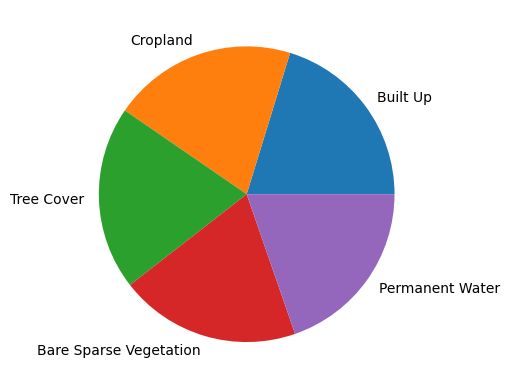

In [5]:
import matplotlib.pyplot as plt

train_df['tag'].value_counts(normalize=False).to_frame().plot.pie(y='count')
plt.ylabel('')
plt.legend().remove()
plt.show()

The classes are a little less balanced in the test data, and that's fine.

In [6]:
test_df['tag'].value_counts(normalize=True).to_frame().T

tag,Permanent Water,Bare Sparse Vegetation,Tree Cover,Cropland,Built Up
proportion,0.217984,0.212534,0.19346,0.190736,0.185286


Next let's use TSNE to add x/y coordinates based on our image embeddings.

In [7]:
from sklearn.manifold import TSNE

train_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
train_df[['x', 'y']] = train_reducer.fit_transform(X=train_df['value'].apply(func=pd.Series))
test_reducer = TSNE(random_state=2026, verbose=True, n_jobs=1, perplexity=20.0, init='pca')
test_df[['x', 'y']] = test_reducer.fit_transform(X=test_df['value'].apply(func=pd.Series))

[t-SNE] Computing 61 nearest neighbors...
[t-SNE] Indexed 2133 samples in 0.016s...
[t-SNE] Computed neighbors for 2133 samples in 0.580s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2133
[t-SNE] Computed conditional probabilities for sample 2000 / 2133
[t-SNE] Computed conditional probabilities for sample 2133 / 2133
[t-SNE] Mean sigma: 3.561316
[t-SNE] KL divergence after 250 iterations with early exaggeration: 70.717911
[t-SNE] KL divergence after 1000 iterations: 1.343451
[t-SNE] Computing 61 nearest neighbors...
[t-SNE] Indexed 367 samples in 0.003s...
[t-SNE] Computed neighbors for 367 samples in 0.037s...
[t-SNE] Computed conditional probabilities for sample 367 / 367
[t-SNE] Mean sigma: 4.617516
[t-SNE] KL divergence after 250 iterations with early exaggeration: 58.278927
[t-SNE] KL divergence after 1000 iterations: 0.635864


Let's use our x/y coordinates to make an interactive scatter plot showing our images colored according to their classes.

In [8]:
from bokeh.models import ColumnDataSource
from bokeh.models import HoverTool

from bokeh.plotting import figure
from bokeh.plotting import output_notebook
from bokeh.plotting import show
from bokeh.palettes import Turbo256
from bokeh.transform import factor_cmap

output_notebook()

datasource = ColumnDataSource(train_df[['png', 'tag', 'x', 'y']].sample(n=min(len(train_df) - 1, 10000)))
factor_count = max(train_df['tag'].nunique(), 3)
indices = np.linspace(0, len(Turbo256)-1, factor_count, dtype=int)
palette = [Turbo256[index] for index in indices]
mapper = factor_cmap(field_name = 'tag', palette=palette, factors=train_df['tag'].unique().tolist(), start=0, end=factor_count-1, )

plot_figure = figure(title='TSNE projection: land cover', width=1000, height=800, tools=('pan, wheel_zoom, reset'))

plot_figure.add_tools(HoverTool(tooltips="""
<div>
    <div>
        <img src='@png' style='float: left; margin: 5px 5px 5px 5px'/>
    </div>
    <div>
        <span style='font-size: 18px'>@tag</span>
    </div>
</div>
"""))

plot_figure.scatter(x='x', y='y', source=datasource, line_alpha=0.6, fill_alpha=0.6, size=8, color=mapper)
show(plot_figure)

Loading BokehJS ...

What do we see? Most of our data clusters nicely into tight clusters aligned with our classes. We have a few difficult cases, but not a lot. Let's make a static plot with our thumbnails.

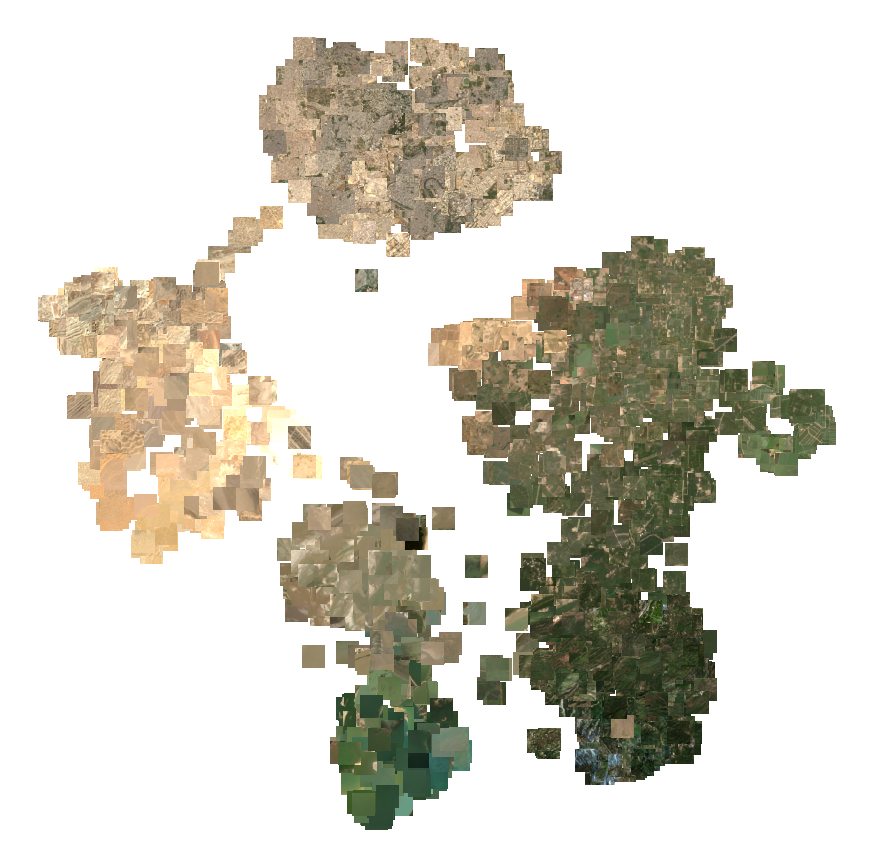

In [9]:
import base64
import io
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image

# we recycled some PNG encoding code above, and we need to postprocess it for using with matplotlib
train_df['PNG'] = train_df['png'].str.replace('^data:image/png;base64,', '', regex=True)

fig, ax = plt.subplots(figsize=(11, 11))

for index, row in train_df.iterrows():
    img_bytes = base64.b64decode(row["PNG"])
    img = Image.open(io.BytesIO(img_bytes))
    imagebox = OffsetImage(img, zoom=0.5)
    ab = AnnotationBbox(imagebox, (row["x"], row["y"]), frameon=False, pad=0)
    ax.add_artist(ab)
ax.scatter(train_df["x"], train_df["y"], alpha=0)
ax.axis('off')
plt.show()

We would like our model to distinguish our classes by their textures and the objects in them, but it looks like what we have is color palette information. Let's build a model and see what we get.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

logreg = LogisticRegression(max_iter=500, tol=1e-12, verbose=0, ).fit(train_df['value'].apply(func=pd.Series), train_df['tag'],)
print('model fit in {} iterations'.format(logreg.n_iter_[0]))
print('accuracy: {:5.4f}'.format(accuracy_score(y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series)))))
print('f1: {:5.4f}'.format(f1_score(average='weighted', y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series)))))
print(classification_report(zero_division=0.0, y_true=test_df['tag'], y_pred=logreg.predict(X=test_df['value'].apply(func=pd.Series))))

model fit in 484 iterations
accuracy: 0.9700
f1: 0.9700
                        precision    recall  f1-score   support

Bare Sparse Vegetation       0.96      1.00      0.98        78
              Built Up       0.99      1.00      0.99        68
              Cropland       0.93      0.94      0.94        70
       Permanent Water       0.99      0.96      0.97        80
            Tree Cover       0.99      0.94      0.96        71

              accuracy                           0.97       367
             macro avg       0.97      0.97      0.97       367
          weighted avg       0.97      0.97      0.97       367



Our model is nearly perfect in four of our five classes. Nice. Let's look at our model probabilities.

<Axes: xlabel='probability', ylabel='Count'>

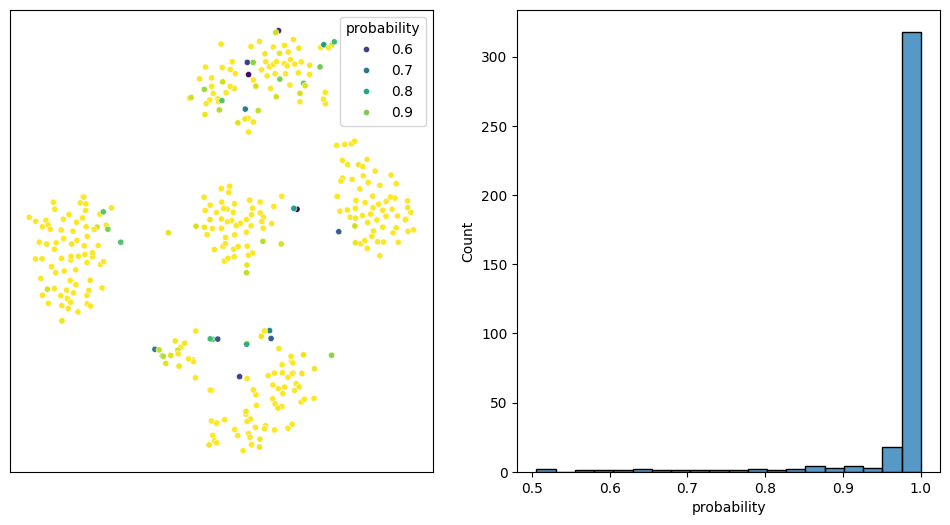

In [11]:
import warnings
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

plot_df = test_df[['x', 'y']].copy()
plot_df['probability'] = np.max(logreg.predict_proba(X=test_df['value'].apply(func=pd.Series)), axis=1)

fig, ax = plt.subplots(ncols=2, figsize=(12, 6))
sns.scatterplot(ax=ax[0], data=plot_df, x='x', y='y', hue='probability', palette='viridis', s=20)
ax[0].set(xlabel=None)
ax[0].set(ylabel=None)
ax[0].set(xticklabels=[])
ax[0].set(yticklabels=[])
ax[0].tick_params(axis='both', which='both', length=0)
sns.histplot(ax=ax[1], data=plot_df, x='probability', bins=20)

Our test data is even better behaved than our training data. Yay!